# Fase 5: validação walk-forward

Para cada época de 2021/22 a 2024/25, cada modelo é treinado com todas as épocas
anteriores e prevê essa época (1 224 jogos no total).
Medidas: log loss (principal), RPS (padrão nos estudos de futebol), Brier e acerto.

In [12]:
import sqlite3
import sys
from contextlib import closing
from pathlib import Path

import numpy as np
import pandas as pd

PASTA_PROJETO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PASTA_PROJETO / "etl"))
import func.avaliacao as av
from func.variaveis import colunas_do_modelo

with closing(sqlite3.connect(PASTA_PROJETO / "dados" / "futebol.db")) as ligacao:
    variaveis = pd.read_sql("SELECT * FROM variaveis ORDER BY Data, JogoID", ligacao, parse_dates=["Data"])
    jogos = pd.read_sql("SELECT JogoID, Epoca, Data, EquipaCasa, EquipaFora, GolosCasa, GolosFora FROM jogos", ligacao)

print(variaveis.groupby("Uso")["JogoID"].count())

Uso
Aquecimento     306
Previsão         72
Teste           306
Treino          918
Validação      1224
Name: JogoID, dtype: int64


In [13]:
import configuracao as cfg

def frequencias(treino, teste):
    f = treino["Resultado"].value_counts(normalize=True).reindex(cfg.RESULTADOS_VALIDOS).to_numpy()
    return np.tile(f, (len(teste), 1))


def elo_escaloes(treino, teste):
    _, limites = pd.qcut(treino["DifElo"], 5, retbins=True)
    limites[0], limites[-1] = -np.inf, np.inf
    tabela = pd.crosstab(pd.cut(treino["DifElo"], limites), treino["Resultado"], normalize="index")[cfg.RESULTADOS_VALIDOS]
    return tabela.loc[pd.cut(teste["DifElo"], limites)].to_numpy()


def odds_abertura(treino, teste):
    return teste[["ProbOddsCasa", "ProbOddsEmpate", "ProbOddsFora"]].to_numpy()


def odds_fecho(treino, teste):
    return teste[["ProbOddsFechoCasa", "ProbOddsFechoEmpate", "ProbOddsFechoFora"]].to_numpy()


resultados = {
    "Frequências": av.walk_forward(variaveis, frequencias),
    "Elo por escalões": av.walk_forward(variaveis, elo_escaloes),
    "Odds de abertura": av.walk_forward(variaveis, odds_abertura),
    "Odds de fecho": av.walk_forward(variaveis, odds_fecho),
}
av.resumo(resultados)

,Modelo,Acerto,LogLoss,Brier,RPS,ECE,LL 21-22,LL 22-23,LL 23-24,LL 24-25
0,Odds de fecho,0.5743,0.9024,0.5304,0.1778,0.0254,0.9179,0.8629,0.9036,0.9251
1,Odds de abertura,0.5719,0.9082,0.5341,0.1793,0.0271,0.9228,0.8686,0.9081,0.9333
2,Elo por escalões,0.5466,0.9470,0.5586,0.1904,0.0219,0.9696,0.8964,0.9471,0.9749
3,Frequências,0.4379,1.0709,0.6480,0.2321,0.0058,1.0952,1.0397,1.0718,1.0768


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def regressao(colunas):
    """Cria um previsor: regressão logística com as colunas indicadas."""
    def previsor(treino, teste):
        modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
        modelo.fit(treino[colunas], treino["Resultado"])
        return av.prever(modelo, teste[colunas])
    return previsor


TODAS = colunas_do_modelo(variaveis)
DIFERENCAS = [c for c in TODAS if c.startswith("Dif") or c.startswith("Equilibrio")
              or c.endswith("Dif") or c == "PiDifEsperada"]
SO_ELO = ["DifElo", "EquilibrioElo"]
SO_PI = ["PiDifEsperada", "EquilibrioPi"]
SO_GAP = ["GapFalhadosDif", "GapBalizaDif", "GapCantosDif", "EquilibrioElo"]
RATINGS = ["DifElo", "PiDifEsperada", "GapFalhadosDif", "GapBalizaDif", "GapCantosDif",
           "EquilibrioElo", "EquilibrioPi"]

resultados.update({
    "Regressão, 37 variáveis": av.walk_forward(variaveis, regressao(TODAS)),
    "Regressão, diferenças": av.walk_forward(variaveis, regressao(DIFERENCAS)),
    "Regressão, só Elo": av.walk_forward(variaveis, regressao(SO_ELO)),
    "Regressão, só pi": av.walk_forward(variaveis, regressao(SO_PI)),
    "Regressão, só GAP": av.walk_forward(variaveis, regressao(SO_GAP)),
    "Regressão, Elo + pi + GAP": av.walk_forward(variaveis, regressao(RATINGS)),
})
av.resumo(resultados)

,Modelo,Acerto,LogLoss,Brier,RPS,ECE,LL 21-22,LL 22-23,LL 23-24,LL 24-25
0,Odds de fecho,0.5743,0.9024,0.5304,0.1778,0.0254,0.9179,0.8629,0.9036,0.9251
1,Odds de abertura,0.5719,0.9082,0.5341,0.1793,0.0271,0.9228,0.8686,0.9081,0.9333
2,"Regressão, só GAP",0.5523,0.9184,0.5403,0.1813,0.0281,0.9402,0.8833,0.9130,0.9371
3,"Regressão, Elo + pi + GAP",0.5490,0.9202,0.5406,0.1816,0.0328,0.9392,0.8885,0.9140,0.9390
4,"Regressão, só pi",0.5507,0.9233,0.5433,0.1838,0.0383,0.9370,0.8844,0.9200,0.9520
5,"Regressão, diferenças",0.5490,0.9258,0.5443,0.1825,0.0344,0.9500,0.8918,0.9214,0.9399
6,"Regressão, só Elo",0.5433,0.9268,0.5471,0.1854,0.0408,0.9419,0.8881,0.9302,0.9470
7,"Regressão, 37 variáveis",0.5482,0.9379,0.5521,0.1855,0.0420,0.9506,0.9100,0.9352,0.9559
8,Elo por escalões,0.5466,0.9470,0.5586,0.1904,0.0219,0.9696,0.8964,0.9471,0.9749
9,Frequências,0.4379,1.0709,0.6480,0.2321,0.0058,1.0952,1.0397,1.0718,1.0768


In [15]:
import func.ordinal as ordinal

# O modelo do artigo dos GAP: regressão ordinal só com as 3 diferenças
resultados["Ordinal GAP"] = av.walk_forward(
    variaveis, ordinal.criar_previsor(["GapFalhadosDif", "GapBalizaDif", "GapCantosDif"]))

In [16]:
import func.dixon_coles as dc

# Demora cerca de 40 segundos: o modelo volta a ser ajustado todas as semanas
resultados["Dixon-Coles"] = av.walk_forward(variaveis, dc.criar_previsor(jogos))
av.resumo(resultados)

,Modelo,Acerto,LogLoss,Brier,RPS,ECE,LL 21-22,LL 22-23,LL 23-24,LL 24-25
0,Odds de fecho,0.5743,0.9024,0.5304,0.1778,0.0254,0.9179,0.8629,0.9036,0.9251
1,Odds de abertura,0.5719,0.9082,0.5341,0.1793,0.0271,0.9228,0.8686,0.9081,0.9333
2,Ordinal GAP,0.5596,0.9150,0.5385,0.1812,0.0301,0.9253,0.8865,0.9117,0.9363
3,"Regressão, só GAP",0.5523,0.9184,0.5403,0.1813,0.0281,0.9402,0.8833,0.9130,0.9371
4,"Regressão, Elo + pi + GAP",0.5490,0.9202,0.5406,0.1816,0.0328,0.9392,0.8885,0.9140,0.9390
5,"Regressão, só pi",0.5507,0.9233,0.5433,0.1838,0.0383,0.9370,0.8844,0.9200,0.9520
6,"Regressão, diferenças",0.5490,0.9258,0.5443,0.1825,0.0344,0.9500,0.8918,0.9214,0.9399
7,"Regressão, só Elo",0.5433,0.9268,0.5471,0.1854,0.0408,0.9419,0.8881,0.9302,0.9470
8,Dixon-Coles,0.5490,0.9280,0.5464,0.1843,0.0395,0.9428,0.8884,0.9322,0.9487
9,"Regressão, 37 variáveis",0.5482,0.9379,0.5521,0.1855,0.0420,0.9506,0.9100,0.9352,0.9559


In [17]:
import func.boosting as gb

previsor_gb = gb.criar_previsor(colunas_do_modelo(variaveis))
resultados["Boosting"] = av.walk_forward(variaveis, previsor_gb)
print(previsor_gb.escolhidos)
av.resumo(resultados)

{'21-22': {'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 100, 'max_iter': 25}, '22-23': {'learning_rate': 0.01, 'max_depth': 2, 'min_samples_leaf': 50, 'max_iter': 200}, '23-24': {'learning_rate': 0.02, 'max_depth': 1, 'min_samples_leaf': 50, 'max_iter': 200}, '24-25': {'learning_rate': 0.05, 'max_depth': 1, 'min_samples_leaf': 50, 'max_iter': 50}}


,Modelo,Acerto,LogLoss,Brier,RPS,ECE,LL 21-22,LL 22-23,LL 23-24,LL 24-25
0,Odds de fecho,0.5743,0.9024,0.5304,0.1778,0.0254,0.9179,0.8629,0.9036,0.9251
1,Odds de abertura,0.5719,0.9082,0.5341,0.1793,0.0271,0.9228,0.8686,0.9081,0.9333
2,Ordinal GAP,0.5596,0.9150,0.5385,0.1812,0.0301,0.9253,0.8865,0.9117,0.9363
3,"Regressão, só GAP",0.5523,0.9184,0.5403,0.1813,0.0281,0.9402,0.8833,0.9130,0.9371
4,"Regressão, Elo + pi + GAP",0.5490,0.9202,0.5406,0.1816,0.0328,0.9392,0.8885,0.9140,0.9390
5,"Regressão, só pi",0.5507,0.9233,0.5433,0.1838,0.0383,0.9370,0.8844,0.9200,0.9520
6,Boosting,0.5556,0.9237,0.5430,0.1833,0.0297,0.9311,0.9014,0.9258,0.9363
7,"Regressão, diferenças",0.5490,0.9258,0.5443,0.1825,0.0344,0.9500,0.8918,0.9214,0.9399
8,"Regressão, só Elo",0.5433,0.9268,0.5471,0.1854,0.0408,0.9419,0.8881,0.9302,0.9470
9,Dixon-Coles,0.5490,0.9280,0.5464,0.1843,0.0395,0.9428,0.8884,0.9322,0.9487


In [18]:
# As 4 candidatas, definidas ANTES de ver os resultados
COMBINACOES = {
    "Ordinal + DC": ["Ordinal GAP", "Dixon-Coles"],
    "Ordinal + GB": ["Ordinal GAP", "Boosting"],
    "DC + GB": ["Dixon-Coles", "Boosting"],
    "Ordinal + DC + GB": ["Ordinal GAP", "Dixon-Coles", "Boosting"],
}
for nome, modelos in COMBINACOES.items():
    resultados[nome] = av.media_geometrica([resultados[m] for m in modelos])

# Critérios: log loss, épocas em que ganha à Ordinal e bootstrap
base = resultados["Ordinal GAP"].groupby("Epoca")["LogLoss"].mean()
for nome in COMBINACOES:
    melhores = (resultados[nome].groupby("Epoca")["LogLoss"].mean() < base).sum()
    print(f"{nome}: {av.comparar(resultados[nome], resultados['Ordinal GAP'])}, melhor em {melhores} de 4 épocas")
av.resumo(resultados)

Ordinal + DC: (np.float64(-0.0008), np.float64(-0.0075), np.float64(0.0055)), melhor em 2 de 4 épocas
Ordinal + GB: (np.float64(0.0006), np.float64(-0.0043), np.float64(0.0053)), melhor em 2 de 4 épocas
DC + GB: (np.float64(0.0037), np.float64(-0.0056), np.float64(0.0124)), melhor em 2 de 4 épocas
Ordinal + DC + GB: (np.float64(-0.0009), np.float64(-0.007), np.float64(0.005)), melhor em 2 de 4 épocas


,Modelo,Acerto,LogLoss,Brier,RPS,ECE,LL 21-22,LL 22-23,LL 23-24,LL 24-25
0,Odds de fecho,0.5743,0.9024,0.5304,0.1778,0.0254,0.9179,0.8629,0.9036,0.9251
1,Odds de abertura,0.5719,0.9082,0.5341,0.1793,0.0271,0.9228,0.8686,0.9081,0.9333
2,Ordinal + DC,0.5572,0.9141,0.5377,0.1806,0.0299,0.9292,0.8792,0.9148,0.9334
3,Ordinal + DC + GB,0.5531,0.9141,0.5375,0.1808,0.0264,0.9260,0.8827,0.9156,0.9320
4,Ordinal GAP,0.5596,0.9150,0.5385,0.1812,0.0301,0.9253,0.8865,0.9117,0.9363
5,Ordinal + GB,0.5531,0.9155,0.5386,0.1814,0.0291,0.9238,0.8899,0.9156,0.9328
6,"Regressão, só GAP",0.5523,0.9184,0.5403,0.1813,0.0281,0.9402,0.8833,0.9130,0.9371
7,DC + GB,0.5580,0.9186,0.5401,0.1819,0.0304,0.9304,0.8859,0.9221,0.9362
8,"Regressão, Elo + pi + GAP",0.5490,0.9202,0.5406,0.1816,0.0328,0.9392,0.8885,0.9140,0.9390
9,"Regressão, só pi",0.5507,0.9233,0.5433,0.1838,0.0383,0.9370,0.8844,0.9200,0.9520


In [19]:
comparacoes = [("Regressão, só GAP", "Regressão, só Elo"),
               ("Regressão, só GAP", "Regressão, 37 variáveis"),
               ("Regressão, só GAP", "Odds de abertura"),
               ("Regressão, só GAP", "Odds de fecho")]
linhas = []
for a, b in comparacoes:
    diferenca, minimo, maximo = av.comparar(resultados[a], resultados[b])
    linhas.append({"Comparação": f"{a} contra {b}", "Diferença": diferenca,
                   "Mínimo": minimo, "Máximo": maximo,
                   "Pode ser sorte?": "Sim" if minimo < 0 < maximo else "Não"})
pd.DataFrame(linhas)
print("Dixon-Coles vs só GAP:", av.comparar(resultados["Dixon-Coles"], resultados["Regressão, só GAP"]))
print("Boosting vs só GAP:", av.comparar(resultados["Boosting"], resultados["Regressão, só GAP"]))

Dixon-Coles vs só GAP: (np.float64(0.0096), np.float64(-0.0043), np.float64(0.023))
Boosting vs só GAP: (np.float64(0.0053), np.float64(-0.0044), np.float64(0.0146))


## Calibração

As percentagens são realistas? Os jogos agrupam-se pela probabilidade prevista
e compara-se com a frequência com que o resultado aconteceu.
Em cima da diagonal = calibração perfeita. ECE: 0 = perfeito.

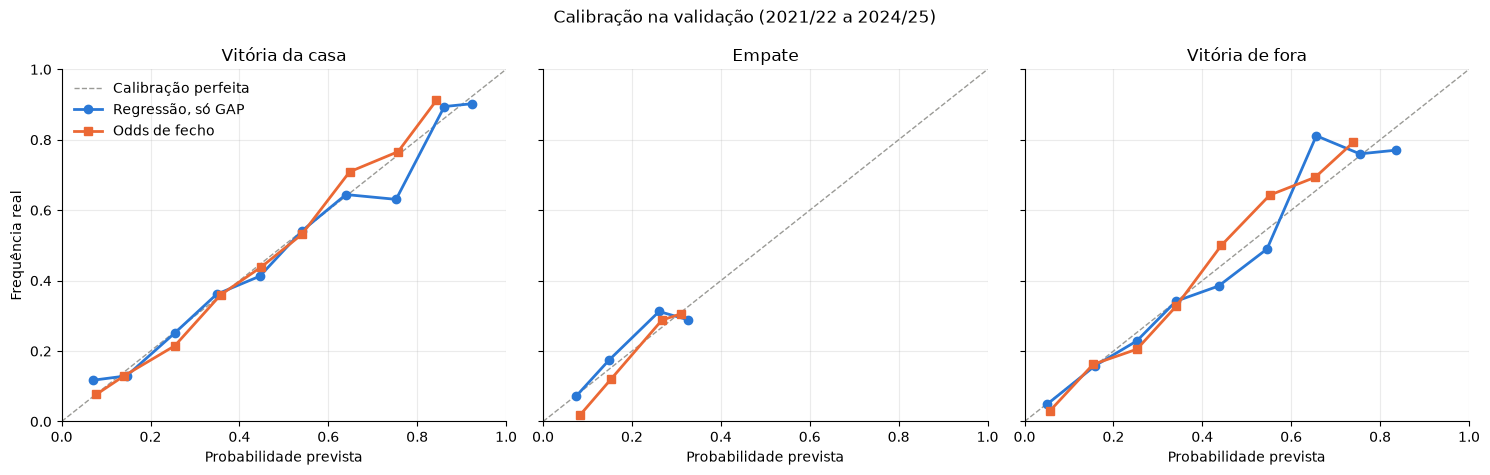

In [20]:
import matplotlib.pyplot as plt

# Cores e símbolos fixos por ordem: azul e círculo para o 1.º modelo,
# laranja e quadrado para o 2.º (cores testadas para daltonismo)
CORES = ["#2a78d6", "#eb6834"]
MARCADORES = ["o", "s"]
NOMES = {"H": "Vitória da casa", "D": "Empate", "A": "Vitória de fora"}


def grafico_calibracao(resultados_por_modelo, grupos=10, minimo_jogos=20):
    fig, eixos = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
    for eixo, resultado in zip(eixos, cfg.RESULTADOS_VALIDOS):
        eixo.plot([0, 1], [0, 1], linestyle="--", linewidth=1, color="#9a9a96", label="Calibração perfeita")
        for (nome, r), cor, marcador in zip(resultados_por_modelo.items(), CORES, MARCADORES):
            t = av.tabela_calibracao(r, grupos)
            # Grupos com poucos jogos dão pontos que saltam ao acaso: não se mostram
            t = t[(t["Resultado"] == resultado) & (t["Jogos"] >= minimo_jogos)]
            eixo.plot(t["Previsto"], t["Real"], color=cor, marker=marcador, linewidth=2, markersize=6, label=nome)
        eixo.set_title(NOMES[resultado])
        eixo.set_xlabel("Probabilidade prevista")
        eixo.set_xlim(0, 1)
        eixo.set_ylim(0, 1)
        eixo.grid(alpha=0.25)
        for lado in ["top", "right"]:
            eixo.spines[lado].set_visible(False)
    eixos[0].set_ylabel("Frequência real")
    eixos[0].legend(loc="upper left", frameon=False)
    fig.suptitle("Calibração na validação (2021/22 a 2024/25)")
    fig.tight_layout()
    return fig


grafico_calibracao({"Regressão, só GAP": resultados["Regressão, só GAP"],
                    "Odds de fecho": resultados["Odds de fecho"]});

In [21]:
pd.DataFrame({nome: av.ece_por_resultado(r) for nome, r in resultados.items()}).T.sort_values("Média")

Resultado,H,D,A,Média
Frequências,0.0065,0.0021,0.0087,0.0058
Elo por escalões,0.0120,0.0252,0.0283,0.0219
Odds de fecho,0.0177,0.0226,0.0358,0.0254
Ordinal + DC + GB,0.0184,0.0282,0.0327,0.0264
Odds de abertura,0.0273,0.0236,0.0303,0.0271
"Regressão, só GAP",0.0255,0.0359,0.0228,0.0281
Ordinal + GB,0.0234,0.0356,0.0282,0.0291
Boosting,0.0270,0.0365,0.0256,0.0297
Ordinal + DC,0.0159,0.0332,0.0404,0.0299
Ordinal GAP,0.0307,0.0294,0.0303,0.0301


In [ ]:
import configuracao as cfg

# Resultados OFICIAIS da fase 5. Só se gravam uma vez: se o ficheiro já existir,
# não se substitui (voltar a correr este notebook agora usa os parâmetros da fase 6).
pasta = cfg.PASTA_PROJETO / "dados"
ficheiros = {
    "resumo_validacao.csv": av.resumo(resultados),
    "previsoes_validacao.csv": pd.concat([r.assign(Modelo=nome) for nome, r in resultados.items()]),
}
for nome, tabela in ficheiros.items():
    caminho = pasta / nome
    if caminho.exists():
        print(f"{nome} já existe: não foi substituído (resultados oficiais da fase 5)")
    else:
        tabela.to_csv(caminho, index=False)
        print(f"{nome} gravado")